# Prova completa — Sistemi di gestione dati e storage distribuito

**Obiettivo:** download e analisi del dataset pubblico, conversione CSV → JSON/Parquet/Avro, generazione file di diverse dimensioni, benchmark completo HDFS/Ozone con **3 ripetizioni** e verifica dei metadati.

Le celle richiamano il codice in `src/`; i risultati vengono **generati da questa esecuzione**, senza leggere report precedenti. Avviare da Jupyter nel container Docker, dopo `docker compose up -d --build`.

**Importante:** Run All include download, conversione (~2,2 milioni di record), creazione di 1 GiB e 24 cicli di trasferimento. Richiede tempo e spazio disponibile; non eseguire altri benchmark contemporaneamente.

In [1]:
from pathlib import Path
import os
import sys
import pandas as pd
from IPython.display import display, Image

# Jupyter apre il notebook in notebooks/, ma il codice Python si trova in src/.
# La radice del repository viene individuata tra la directory corrente e i suoi antenati.
CWD = Path.cwd().resolve()
ROOT = next((directory for directory in (CWD, *CWD.parents)
             if (directory / "src" / "benchmark.py").is_file()), None)
if ROOT is None:
    raise RuntimeError(
        f"Repository non trovato partendo da {CWD}. "
        "Verificare che src/benchmark.py sia presente nel volume montato in Jupyter."
    )

# I moduli esistenti utilizzano percorsi relativi (data/, results/).
# La radice viene impostata anche come directory di lavoro del kernel.
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
(ROOT / "results").mkdir(exist_ok=True)
print("Repository:", ROOT)
print("Directory di lavoro:", Path.cwd())


Repository: /home/jovyan/work
Directory di lavoro: /home/jovyan/work


## 1. Dataset pubblico

Fonte: Kaggle, *NYC Citywide Payroll Data* (versione esplicitamente fissata nel modulo `dataset_download.py`). La prima esecuzione richiede accesso alla rete e spazio disponibile.

In [2]:
from src.dataset_download import download_dataset
csv_files = download_dataset()
from src.converters import CSV_PATH
assert CSV_PATH.is_file(), f"CSV atteso non trovato in {CSV_PATH}; verificare la destinazione di download_dataset()"
print(f"Dataset: {CSV_PATH.name} — {CSV_PATH.stat().st_size / 1024**2:.2f} MiB")

100%|██████████| 52.1M/52.1M [00:02<00:00, 19.7MB/s]


Extracting files...
Dataset disponibile in: /home/jovyan/work/data/original
Citywide_Payroll_Data__Fiscal_Year_.csv: 395.11 MiB
Dataset: Citywide_Payroll_Data__Fiscal_Year_.csv — 395.11 MiB


## 2. Analisi esplorativa

Numero record, colonne, valori mancanti e grafici. Analisi a chunk per limitare l'uso della RAM.

In [3]:
from src.dataset_analysis import analyze_dataset
analyze_dataset()

=== DATASET ANALYSIS ===
File: Citywide_Payroll_Data__Fiscal_Year_.csv
Dimensione: 395.11 MiB

Colonne:
 - Fiscal Year
 - Agency Name
 - Last Name
 - First Name
 - Mid Init
 - Agency Start Date
 - Work Location Borough
 - Title Description
 - Leave Status as of June 30
 - Base Salary
 - Pay Basis
 - Regular Hours
 - Regular Gross Paid
 - OT Hours
 - Total OT Paid
 - Total Other Pay

Numero righe: 2,194,488
Numero colonne: 16

Valori mancanti per colonna:
Fiscal Year                        0
Agency Name                        0
Last Name                        942
First Name                       952
Mid Init                      890008
Agency Start Date                  0
Work Location Borough         506214
Title Description                 21
Leave Status as of June 30         0
Base Salary                        0
Pay Basis                          0
Regular Hours                      0
Regular Gross Paid                 0
OT Hours                           0
Total OT Paid          

{'dataset_file': 'Citywide_Payroll_Data__Fiscal_Year_.csv',
 'size_bytes': 414298921,
 'size_mib': 395.11,
 'row_count': 2194488,
 'column_count': 16,
 'total_missing_cells': 1398137,
 'completeness_percent': 96.018,
 'columns': ['Fiscal Year',
  'Agency Name',
  'Last Name',
  'First Name',
  'Mid Init',
  'Agency Start Date',
  'Work Location Borough',
  'Title Description',
  'Leave Status as of June 30',
  'Base Salary',
  'Pay Basis',
  'Regular Hours',
  'Regular Gross Paid',
  'OT Hours',
  'Total OT Paid',
  'Total Other Pay'],
 'missing_values': {'Fiscal Year': 0,
  'Agency Name': 0,
  'Last Name': 942,
  'First Name': 952,
  'Mid Init': 890008,
  'Agency Start Date': 0,
  'Work Location Borough': 506214,
  'Title Description': 21,
  'Leave Status as of June 30': 0,
  'Base Salary': 0,
  'Pay Basis': 0,
  'Regular Hours': 0,
  'Regular Gross Paid': 0,
  'OT Hours': 0,
  'Total OT Paid': 0,
  'Total Other Pay': 0}}

## 3. Conversione e confronto dei formati

Vengono prodotti un file JSON valido (array di record), un file Parquet e un file Avro. Il modulo verifica la corrispondenza del numero di record. Non vengono introdotte compressioni opzionali, per mantenere il confronto previsto dalla traccia.

In [4]:
from src.converters import run_conversions
risultati_formati = run_conversions()
print("Conversioni e verifica completate")
print(risultati_formati)

Record convertiti: 50,000
Record convertiti: 100,000
Record convertiti: 150,000
Record convertiti: 200,000
Record convertiti: 250,000
Record convertiti: 300,000
Record convertiti: 350,000
Record convertiti: 400,000
Record convertiti: 450,000
Record convertiti: 500,000
Record convertiti: 550,000
Record convertiti: 600,000
Record convertiti: 650,000
Record convertiti: 700,000
Record convertiti: 750,000
Record convertiti: 800,000
Record convertiti: 850,000
Record convertiti: 900,000
Record convertiti: 950,000
Record convertiti: 1,000,000
Record convertiti: 1,050,000
Record convertiti: 1,100,000
Record convertiti: 1,150,000
Record convertiti: 1,200,000
Record convertiti: 1,250,000
Record convertiti: 1,300,000
Record convertiti: 1,350,000
Record convertiti: 1,400,000
Record convertiti: 1,450,000
Record convertiti: 1,500,000
Record convertiti: 1,550,000
Record convertiti: 1,600,000
Record convertiti: 1,650,000
Record convertiti: 1,700,000
Record convertiti: 1,750,000
Record convertiti: 1,800

## 4. Generazione dei file di benchmark

Vengono generati, oppure verificati tramite SHA-256, file deterministici da **10 KiB, 50 MiB, 250 MiB e 1 GiB**. Non sono necessari file preparati in sessioni precedenti.

In [5]:
from src.file_generator import generate_benchmark_files
file_generati = generate_benchmark_files()
display(pd.DataFrame(file_generati))

[GENERAZIONE] benchmark_10KiB.bin (10,240 byte)
[GENERAZIONE] benchmark_50MiB.bin (52,428,800 byte)
[GENERAZIONE] benchmark_250MiB.bin (262,144,000 byte)
[GENERAZIONE] benchmark_1GiB.bin (1,073,741,824 byte)

Manifest salvato in: /home/jovyan/work/results/generated_files.json


,name,path,size_bytes,sha256
0,10KiB,/home/jovyan/work/data/generated/benchmark_10K...,10240,b895ef0bd80ed6f2c088acd3892e2bb9a180c7d6574327...
1,50MiB,/home/jovyan/work/data/generated/benchmark_50M...,52428800,c8eff7501fe8081d5cfec74142eda9e4dc923accd8d3b8...
2,250MiB,/home/jovyan/work/data/generated/benchmark_250...,262144000,9aa9f9aed42862882c328aa71cc3aaf434d329583b487b...
3,1GiB,/home/jovyan/work/data/generated/benchmark_1Gi...,1073741824,f32674611f715527acf72aa25147d1a0d5538785f5cd6f...


## 5. Controllo dei servizi

Il benchmark utilizza WebHDFS (`namenode:9870`), Ozone S3 Gateway (`s3g:9878`) e il servizio interno di metrica dei volumi. Prima dell’avvio viene verificata la disponibilità degli endpoint, senza includere tali controlli nei tempi misurati.

In [6]:
from src.storage import HDFSClient, OzoneClient
from src.storage_analysis import snapshot
hdfs_check = HDFSClient()
oz_check = OzoneClient()
try:
    assert hdfs_check.exists("/"), "WebHDFS non raggiungibile"
    oz_check.s3.list_buckets()
    volumi = snapshot()
    print("HDFS, S3 Gateway e storage-metrics raggiungibili")
    print("Volumi letti:", ", ".join(volumi.keys()))
finally:
    hdfs_check.close()

HDFS, S3 Gateway e storage-metrics raggiungibili
Volumi letti: hdfs_name, hdfs_dn1, hdfs_dn2, hdfs_dn3, ozone_scm, ozone_om, ozone_dn, ozone_recon


## 6. Benchmark completo — 3 ripetizioni

- **24 cicli verificati**: 4 dimensioni × 2 sistemi × 3 ripetizioni.
- Identico contenuto, **nome remoto diverso** per ogni caricamento.
- Snapshot storage **prima e dopo ogni upload**, esclusi dal cronometro.
- Upload e download cronometrati separatamente; checksum SHA-256 verificato a ogni ciclo.
- Gli oggetti rimangono nei volumi sino alla fine per consentire la crescita cumulativa.

Viene generato automaticamente un nuovo `run_id`; i file in `results/` derivano dall’esecuzione corrente. Su cluster condiviso da più esperimenti, la stima di incremento spazio può essere influenzata da attività di background e allocazioni precedenti.

In [7]:
from src.benchmark import BenchmarkConfig, run_benchmark
config = BenchmarkConfig(repetitions=3, clean_remote=False, settle_seconds=2.0)
benchmark_result = run_benchmark(config)
run_id = benchmark_result["run_id"]
raw_csv = Path(benchmark_result["raw_csv"])
summary_csv = Path(benchmark_result["summary_csv"])
print("RUN ID:", run_id)
print("Misure:", raw_csv)

Controllo/generazione dei file originali (fuori dal benchmark)...
[RIUTILIZZATO] benchmark_10KiB.bin
[RIUTILIZZATO] benchmark_50MiB.bin
[RIUTILIZZATO] benchmark_250MiB.bin
[RIUTILIZZATO] benchmark_1GiB.bin

Manifest salvato in: /home/jovyan/work/results/generated_files.json
[TEST] HDFS  10KiB  rip. 1/3
       upload=1.080s download=0.100s checksum=OK (1/24)
[TEST] Ozone 10KiB  rip. 1/3
       upload=1.117s download=0.262s checksum=OK (2/24)
[TEST] Ozone 10KiB  rip. 2/3
       upload=0.085s download=0.062s checksum=OK (3/24)
[TEST] HDFS  10KiB  rip. 2/3
       upload=1.042s download=0.095s checksum=OK (4/24)
[TEST] HDFS  10KiB  rip. 3/3
       upload=0.469s download=0.057s checksum=OK (5/24)
[TEST] Ozone 10KiB  rip. 3/3
       upload=0.059s download=0.062s checksum=OK (6/24)
[TEST] HDFS  50MiB  rip. 1/3
       upload=1.480s download=0.516s checksum=OK (7/24)
[TEST] Ozone 50MiB  rip. 1/3
       upload=1.872s download=1.157s checksum=OK (8/24)
[TEST] Ozone 50MiB  rip. 2/3
       upload=1.

## 7. Verifiche quantitative e statistiche

Una tabella con i 24 cicli del run corrente, statistiche aggregate per dimensione e sistema e controllo dell'integrità.

In [8]:
grezzi = pd.read_csv(raw_csv)
riepilogo = pd.read_csv(summary_csv)
attesi = 4 * 2 * config.repetitions
assert len(grezzi) == attesi, f"Attesi {attesi} cicli, trovati {len(grezzi)}"
assert grezzi["verified"].astype(str).str.lower().eq("true").all(), "Checksum non tutti verificati"
assert grezzi["remote_path"].nunique() == attesi, "Percorsi remoti duplicati"
print(f"Cicli verificati: {len(grezzi)}/{attesi}")
display(riepilogo)

Cicli verificati: 24/24


,run_id,size_label,size_bytes,system,completed,upload_mean_s,upload_median_s,upload_stdev_s,download_mean_s,download_median_s,download_stdev_s,upload_mean_mib_s,download_mean_mib_s
0,20261011T145001Z-d31146,10KiB,10240,HDFS,3,0.864012,1.042441,0.342506,0.084010,0.095186,0.023695,0.0131,0.1240
1,20261011T145001Z-d31146,10KiB,10240,Ozone,3,0.420191,0.084914,0.603172,0.128579,0.062298,0.115269,0.0963,0.1174
2,20261011T145001Z-d31146,50MiB,52428800,HDFS,3,1.546899,1.480365,0.440071,0.496835,0.514888,0.032659,34.0941,100.9392
3,20261011T145001Z-d31146,50MiB,52428800,Ozone,3,1.715845,1.649247,0.135663,1.072962,1.056006,0.076778,29.2569,46.7562
4,20261011T145001Z-d31146,250MiB,262144000,HDFS,3,6.323597,5.744559,1.682138,2.453636,2.434531,0.080624,41.2877,101.9622
5,20261011T145001Z-d31146,250MiB,262144000,Ozone,3,8.548865,8.329533,0.465934,5.688359,5.397904,0.922296,29.3000,44.6850
6,20261011T145001Z-d31146,1GiB,1073741824,HDFS,3,33.382429,32.930794,1.795784,14.087759,13.769584,1.832582,30.7330,73.4936
7,20261011T145001Z-d31146,1GiB,1073741824,Ozone,3,37.254508,36.078870,3.496652,28.824103,29.735661,1.990590,27.6426,35.6436


## 8. Grafici: tempi e incremento dello storage

I grafici di spazio rappresentano la variazione dei byte allocati nei volumi Docker rispetto alla baseline, **non** una misura universale dell'overhead fisico. HDFS usa 3 DataNode e Ozone 1 DataNode, entrambi con replica 1; i protocolli di lettura/scrittura differiscono.

benchmark_20261011T145001Z-d31146_upload.png


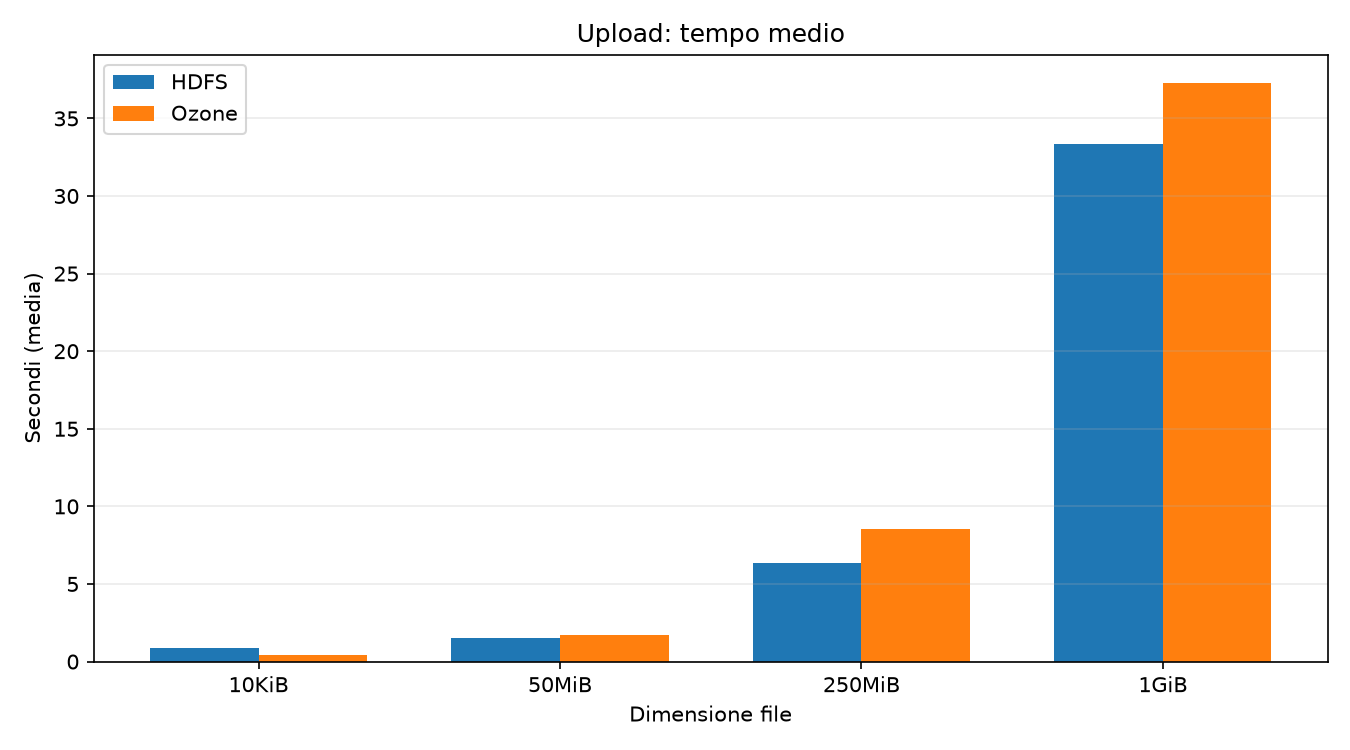

benchmark_20261011T145001Z-d31146_download.png


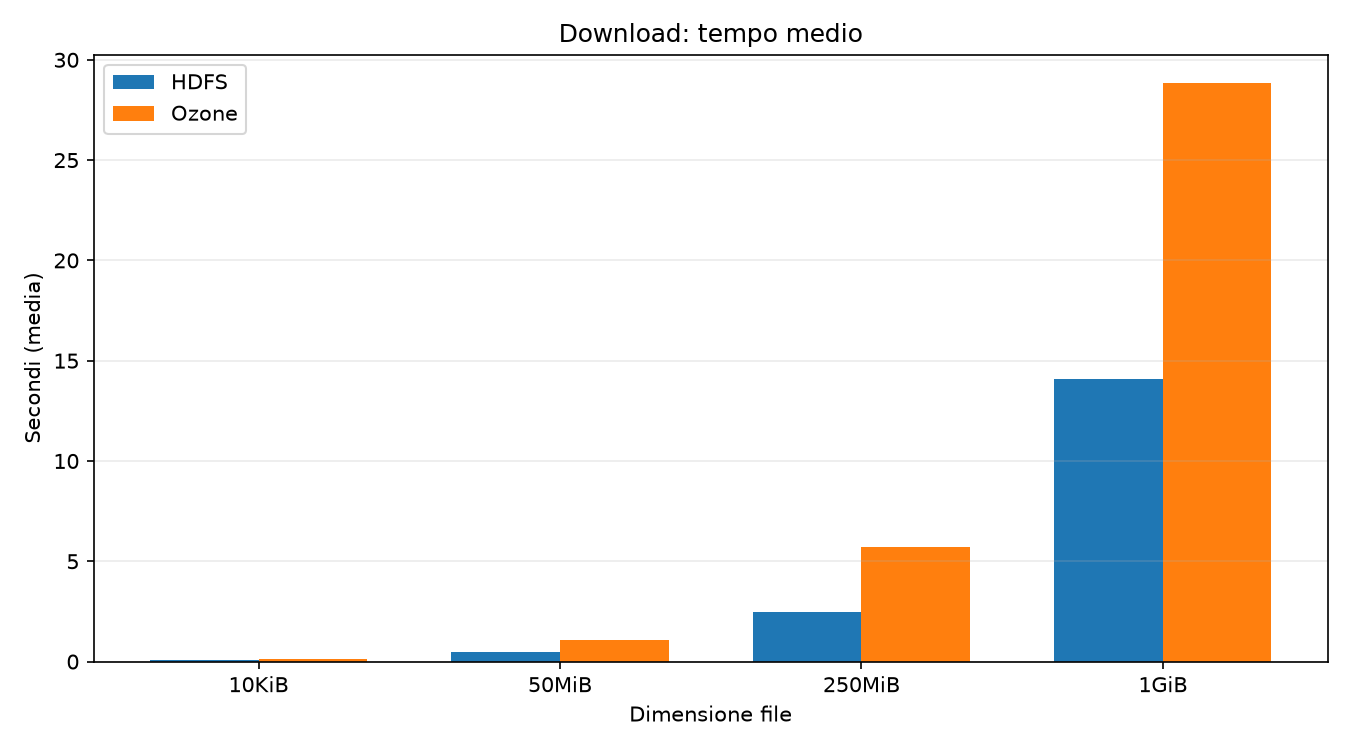

benchmark_20261011T145001Z-d31146_storage_hdfs.png


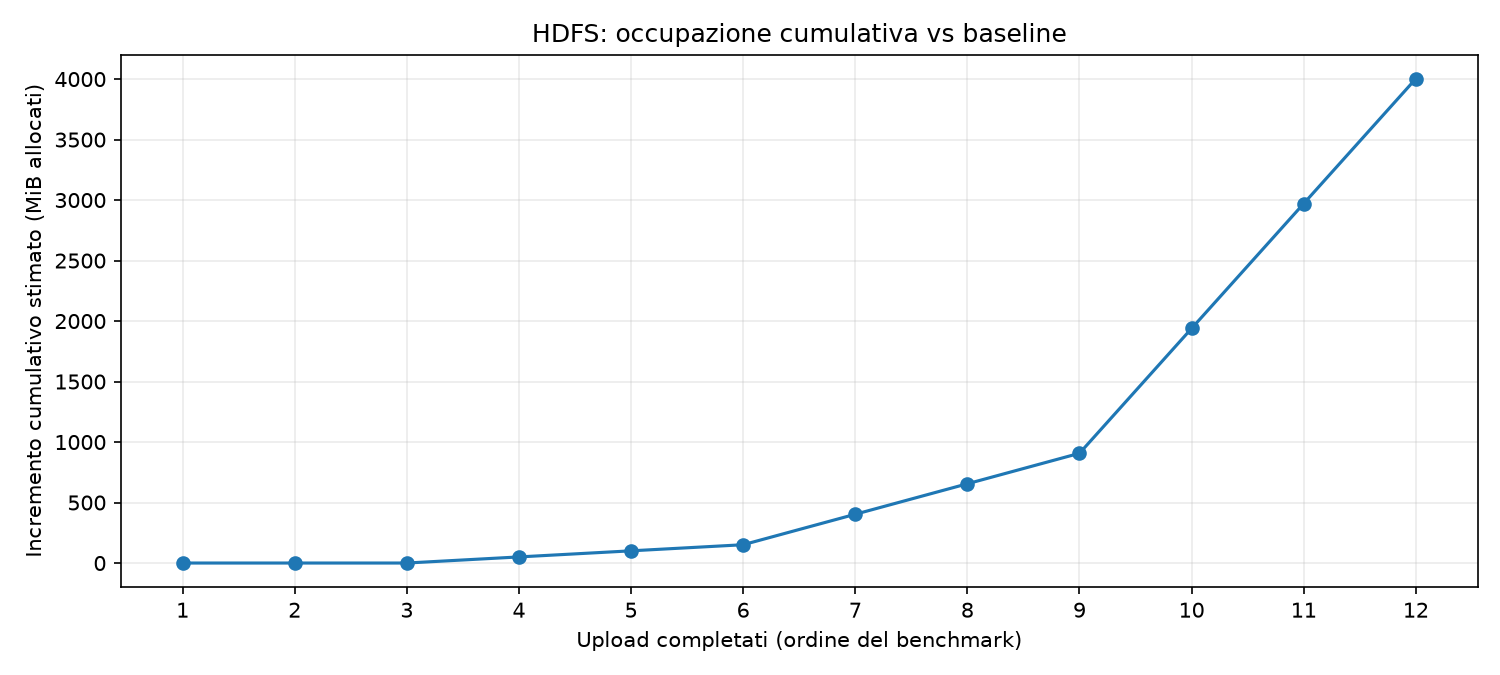

benchmark_20261011T145001Z-d31146_storage_ozone.png


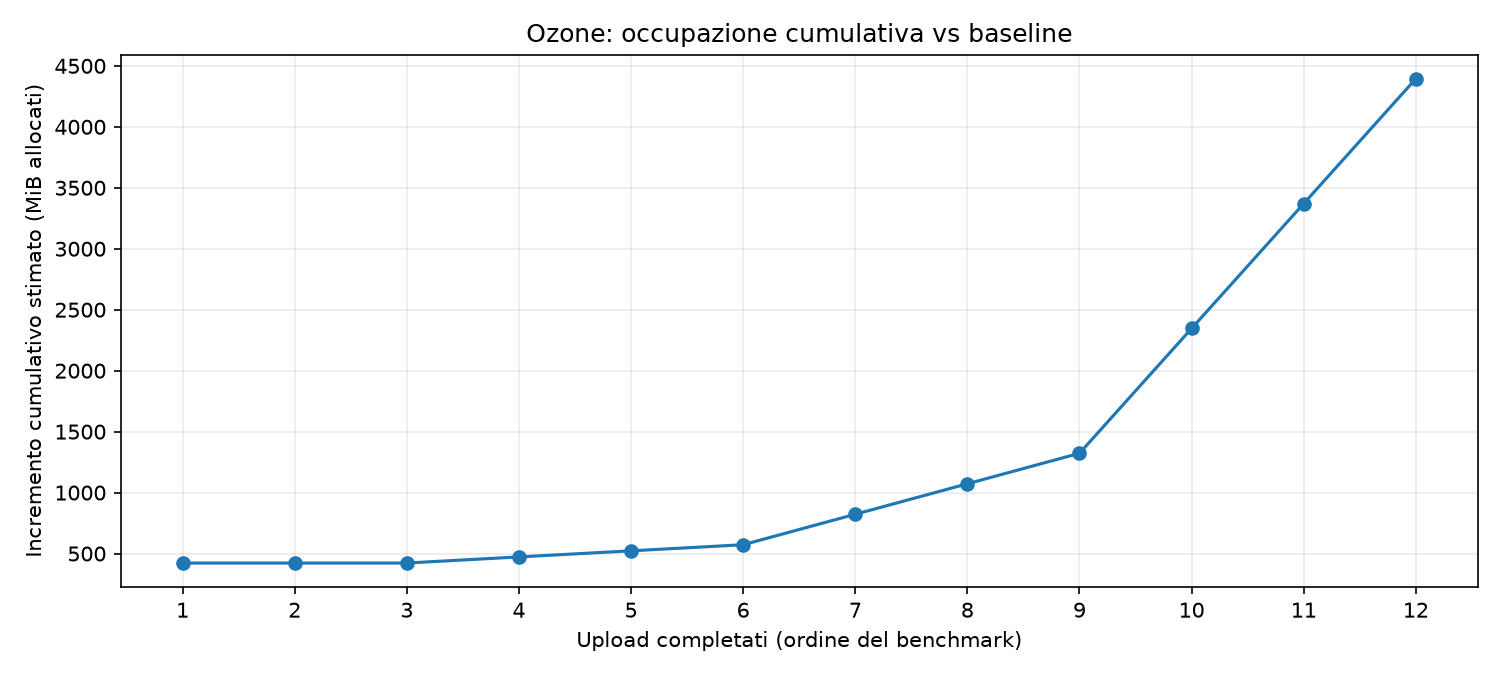

In [9]:
for grafico in benchmark_result["plots"]:
    print(Path(grafico).name)
    display(Image(filename=str(grafico)))

## 9. Verifica dei metadati e dell'organizzazione dello storage

Per contenere la durata del benchmark, viene verificato **un file già caricato per ogni dimensione e sistema** (prima ripetizione). Non vengono effettuati nuovi upload.

**HDFS:** vengono verificati esistenza, dimensione, replica, block size e numero teorico di blocchi; le localizzazioni vengono richieste tramite WebHDFS, quando supportate.

**Ozone:** esistenza del bucket e della key, dimensione `ContentLength`, timestamp, ETag. L'ETag non è prova SHA-256; la verifica d'integrità è già effettuata dal benchmark.

La configurazione `RATIS/ONE` della pipeline Ozone è stata verificata amministrativamente sul cluster: l'API S3 non fornisce direttamente l'ID dei container fisici.

In [10]:
from src.storage_metadata import inspect_benchmark_run
import json
metadata_path = ROOT / "results" / f"benchmark_{run_id}_metadata.json"
metadati = inspect_benchmark_run(raw_csv, bucket=config.ozone_bucket, output_json=metadata_path)
metadati_tabella = pd.DataFrame([{
    "sistema": x["sistema"], "dimensione": x["dimensione"],
    "dimensione_byte": x["dimensione_byte"],
    "block_size_byte": x.get("block_size_byte"),
    "blocchi_attesi": x.get("blocchi_attesi"),
    "replica": x.get("replica"),
    "presente": x.get("presente", x.get("oggetto_presente")),
} for x in metadati])
display(metadati_tabella)
print("Metadati salvati in:", metadata_path)

,sistema,dimensione,dimensione_byte,block_size_byte,blocchi_attesi,replica,presente
0,HDFS,10KiB,10240,134217728.0,1.0,1.0,True
1,Ozone,10KiB,10240,NaN,NaN,NaN,True
2,HDFS,50MiB,52428800,134217728.0,1.0,1.0,True
3,Ozone,50MiB,52428800,NaN,NaN,NaN,True
4,HDFS,250MiB,262144000,134217728.0,2.0,1.0,True
5,Ozone,250MiB,262144000,NaN,NaN,NaN,True
6,HDFS,1GiB,1073741824,134217728.0,8.0,1.0,True
7,Ozone,1GiB,1073741824,NaN,NaN,NaN,True


Metadati salvati in: /home/jovyan/work/results/benchmark_20261011T145001Z-d31146_metadata.json


### 9.1. Collocazione effettiva dei blocchi HDFS

La tabella e il grafico seguenti usano le `BlockLocation` restituite da WebHDFS durante **questa esecuzione**. La suddivisione in blocchi non implica che blocchi diversi siano necessariamente collocati su DataNode diversi. Con fattore di replica 1 ciascun blocco ha una sola replica.


In [11]:
import matplotlib.pyplot as plt

righe_blocchi = []
for voce in metadati:
    if voce["sistema"] != "HDFS":
        continue
    blocchi = (voce.get("block_locations") or {}).get("BlockLocation", [])
    for numero, blocco in enumerate(blocchi, start=1):
        righe_blocchi.append({
            "File": voce["dimensione"],
            "Blocco": numero,
            "Offset (MiB)": round(blocco["offset"] / 1024**2, 3),
            "Dimensione (MiB)": round(blocco["length"] / 1024**2, 3),
            "DataNode": ", ".join(blocco.get("hosts", [])) or "Non disponibile",
        })

blocchi_hdfs = pd.DataFrame(righe_blocchi)
if blocchi_hdfs.empty:
    print("Localizzazioni dei blocchi non disponibili: consultare il JSON dei metadati.")
else:
    display(blocchi_hdfs)
    ordine = ["10KiB", "50MiB", "250MiB", "1GiB"]
    conteggio = pd.crosstab(blocchi_hdfs["File"], blocchi_hdfs["DataNode"])
    conteggio = conteggio.reindex(ordine, fill_value=0)
    ax = conteggio.plot(kind="bar", stacked=True, figsize=(10, 5))
    ax.set_title("HDFS: collocazione effettiva dei blocchi sui DataNode")
    ax.set_xlabel("Dimensione del file")
    ax.set_ylabel("Numero di blocchi")
    ax.legend(title="DataNode", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.xticks(rotation=0)
    plt.tight_layout()
    grafico_blocchi = ROOT / "results" / f"benchmark_{run_id}_hdfs_block_distribution.png"
    plt.savefig(grafico_blocchi, dpi=150, bbox_inches="tight")
    plt.show()
    print("Grafico salvato in:", grafico_blocchi)


,File,Blocco,Offset (MiB),Dimensione (MiB),DataNode
0,10KiB,1,0.0,0.01,hdfs-datanode-3
1,50MiB,1,0.0,50.00,hdfs-datanode-3
2,250MiB,1,0.0,128.00,hdfs-datanode-1
3,250MiB,2,128.0,122.00,hdfs-datanode-1
4,1GiB,1,0.0,128.00,hdfs-datanode-3
5,1GiB,2,128.0,128.00,hdfs-datanode-3
6,1GiB,3,256.0,128.00,hdfs-datanode-3
7,1GiB,4,384.0,128.00,hdfs-datanode-3
8,1GiB,5,512.0,128.00,hdfs-datanode-3
9,1GiB,6,640.0,128.00,hdfs-datanode-3


Grafico salvato in: /home/jovyan/work/results/benchmark_20261011T145001Z-d31146_hdfs_block_distribution.png


### 9.2. Organizzazione logica degli oggetti Ozone

Vengono verificati **bucket, key, dimensione e metadati S3** di un oggetto per ogni dimensione. Il benchmark usa un solo DataNode Ozone con replica RATIS/ONE; l'interfaccia S3 non espone la mappatura fisica degli oggetti sui container/chunk Ozone. La tabella non rappresenta quindi una distribuzione fisica equivalente a quella dei blocchi HDFS.


In [12]:
righe_oggetti = []
for voce in metadati:
    if voce["sistema"] != "Ozone":
        continue
    righe_oggetti.append({
        "File": voce["dimensione"],
        "Bucket": voce["bucket"],
        "Key": voce["key"],
        "Dimensione (MiB)": round(voce["dimensione_byte"] / 1024**2, 3),
        "Bucket presente": voce["bucket_presente"],
        "Oggetto presente": voce["oggetto_presente"],
        "Dimensione verificata": voce["dimensione_verificata"],
        "Ultima modifica": voce.get("ultima_modifica"),
        "ETag": voce.get("etag"),
    })

oggetti_ozone = pd.DataFrame(righe_oggetti)
assert len(oggetti_ozone) == 4, "Attesi quattro oggetti Ozone campione"
assert oggetti_ozone[["Bucket presente", "Oggetto presente", "Dimensione verificata"]].all().all(),     "Uno o più controlli degli oggetti Ozone non sono riusciti"
display(oggetti_ozone)
print("Tutti gli oggetti campione risultano presenti nel bucket, con dimensione corretta.")
print("ETag non è usato come checksum: l'integrità è stata verificata con SHA-256.")


,File,Bucket,Key,Dimensione (MiB),Bucket presente,Oggetto presente,Dimensione verificata,Ultima modifica,ETag
0,10KiB,asdbd-benchmark,performance/20261011T145001Z-d31146/10KiB/rip_...,0.01,True,True,True,2026-10-11T14:50:25+00:00,"""8185658b7df4838b290e81327df068c6"""
1,50MiB,asdbd-benchmark,performance/20261011T145001Z-d31146/50MiB/rip_...,50.00,True,True,True,2026-10-11T14:50:44+00:00,"""f6273979b65f8beb52a14c2f201c02dd-7"""
2,250MiB,asdbd-benchmark,performance/20261011T145001Z-d31146/250MiB/rip...,250.00,True,True,True,2026-10-11T14:51:29+00:00,"""66221857fec075e9f5e89612a77569bf-32"""
3,1GiB,asdbd-benchmark,performance/20261011T145001Z-d31146/1GiB/rip_1...,1024.00,True,True,True,2026-10-11T14:54:15+00:00,"""6bc8b5cf826cf8268e3613140cdda7be-128"""


Tutti gli oggetti campione risultano presenti nel bucket, con dimensione corretta.
ETag non è usato come checksum: l'integrità è stata verificata con SHA-256.


## 10. Conclusioni e limiti metodologici

Le conclusioni devono basarsi **sui risultati della sessione corrente**. I valori sono validi per il laboratorio Docker locale, non rappresentano prestazioni universali dei prodotti:

- HDFS: 3 DataNode, replica 1, WebHDFS.
- Ozone: 1 DataNode, `RATIS/ONE`, S3 Gateway.
- CPU, RAM e disco host condivisi; effetti di cache e allocazione dei container.
- Tre ripetizioni per combinazione: analisi descrittiva, non inferenza statistica robusta.
- L'incremento nei volumi può includere overhead e altre attività interne; non va confuso con la dimensione logica dei file.

In [13]:
# Sintesi numerica, calcolata soltanto sui dati appena prodotti.
colonne = ["size_label", "system", "upload_mean_s", "download_mean_s", "upload_mean_mib_s", "download_mean_mib_s"]
display(riepilogo[colonne].round(3))
print("Dataset, conversioni, 24 cicli, SHA-256, grafici e metadati completati.")

,size_label,system,upload_mean_s,download_mean_s,upload_mean_mib_s,download_mean_mib_s
0,10KiB,HDFS,0.864,0.084,0.013,0.124
1,10KiB,Ozone,0.420,0.129,0.096,0.117
2,50MiB,HDFS,1.547,0.497,34.094,100.939
3,50MiB,Ozone,1.716,1.073,29.257,46.756
4,250MiB,HDFS,6.324,2.454,41.288,101.962
5,250MiB,Ozone,8.549,5.688,29.300,44.685
6,1GiB,HDFS,33.382,14.088,30.733,73.494
7,1GiB,Ozone,37.255,28.824,27.643,35.644


Dataset, conversioni, 24 cicli, SHA-256, grafici e metadati completati.
